In [1]:
!apt-get update
!apt-get install -y libopencv-dev build-essential cmake

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:3 https://cli.github.com/packages stable/main amd64 Packages [358 B]
Get:4 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [2,066 kB]
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Get:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:7 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:8 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:9 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [81.1 kB]
Get:10 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:11 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:13 https://r2u.stat.illinois.edu/ubuntu noble/main 

In [2]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

int main() {
    std::cout << "OpenCV Versiyonu: " << CV_VERSION << std::endl;

    // Colab GPU Bağlantı Kontrolü
    int deviceCount = 0;
    cudaError_t error = cudaGetDeviceCount(&deviceCount);

    if (error == cudaSuccess && deviceCount > 0) {
        std::cout << "Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: " << deviceCount << std::endl;
    } else {
        std::cout << "CUDA Cihazı Bulunamadı veya GPU Aktif Edilmedi!" << std::endl;
    }

    return 0;
}

Writing main.cpp


In [3]:
!g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1
OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [8]:
%%writefile main_motion.cpp
#include <iostream>
#include <opencv2/opencv.hpp>

using namespace cv;
using namespace std;

// YCbCr renk uzayında ten rengi tespiti fonksiyonu
bool isSkinYCbCr(uchar Y, uchar Cr, uchar Cb) {
    return (Cb >= 80 && Cb <= 120 && Cr >= 133 && Cr <= 173);
}

int main() {
    // Google Colab ortamında kameradan doğrudan okuma yapılamadığı için
    // 'haftalıkgörev1.jpeg' dosyasını yükleyip üzerinde yapay bir hareket simülasyonu gerçekleştiriyoruz.
    Mat frame1 = imread("haftalıkgörev1.jpeg");
    if (frame1.empty()) {
        cerr << "Hata: haftalıkgörev1.jpeg dosyası yüklenemedi!" << endl;
        return -1;
    }

    // İkinci kare olarak hafifçe kaydırılmış ve gürültü eklenmiş bir kopya oluşturalım (hareket simülasyonu)
    Mat frame2 = frame1.clone();
    // Görüntünün sağ alt kısmında yapay bir hareketli nesne (örneğin hareket eden el/ten bölgesi) oluşturalım
    rectangle(frame2, Point(150, 150), Point(300, 300), Scalar(100, 120, 180), -1);

    Mat gray1, gray2;
    cvtColor(frame1, gray1, COLOR_BGR2GRAY);
    cvtColor(frame2, gray2, COLOR_BGR2GRAY);

    // İki çerçeve arasındaki farkı bulma (Hareket tespiti)
    Mat diff, thresh;
    absdiff(gray1, gray2, diff);
    threshold(diff, thresh, 25, 255, THRESH_BINARY);

    // Parazitleri temizleme
    dilate(thresh, thresh, Mat(), Point(-1,-1), 2);

    // Hareket eden bölgeleri (konturları) bulma
    vector<vector<Point>> contours;
    findContours(thresh, contours, RETR_EXTERNAL, CHAIN_APPROX_SIMPLE);

    Mat output = frame2.clone();
    Mat ycbcr;
    cvtColor(frame2, ycbcr, COLOR_BGR2YCrCb);

    for (size_t i = 0; i < contours.size(); i++) {
        // Eğer hareket alanı yeterince büyükse (yeterince piksel hareket ettiyse)
        if (contourArea(contours[i]) > 500) {
            Rect roiRect = boundingRect(contours[i]);

            // Sadece ROI içinde çalışacak şekilde piksel taraması yapıp ten tespiti uygulayalım
            for (int r = roiRect.y; r < roiRect.y + roiRect.height; r++) {
                for (int c = roiRect.x; c < roiRect.x + roiRect.width; c++) {
                    if (r >= 0 && r < frame2.rows && c >= 0 && c < frame2.cols) {
                        // Hareket maskesi içinde mi kontrolü
                        if (thresh.at<uchar>(r, c) > 0) {
                            Vec3b p = ycbcr.at<Vec3b>(r, c);
                            if (isSkinYCbCr(p[0], p[1], p[2])) {
                                // Ten bölgesini belirgin yeşil renge boyayalım
                                output.at<Vec3b>(r, c) = Vec3b(0, 255, 0);
                            }
                        }
                    }
                }
            }
            // ROI kutusunu çizelim
            rectangle(output, roiRect, Scalar(255, 0, 0), 2);
        }
    }

    imwrite("hareket_ve_ten_tespiti.jpg", output);
    imwrite("hareket_maskesi.jpg", thresh);
    cout << "İşlem tamamlandı! Sonuçlar kaydedildi." << endl;
    return 0;
}

Writing main_motion.cpp


In [9]:
# C++ Hareket ve Ten tespiti uygulamasını derle ve çalıştır
!g++ main_motion.cpp -o app_motion `pkg-config --cflags --libs opencv4`
!./app_motion

İşlem tamamlandı! Sonuçlar kaydedildi.


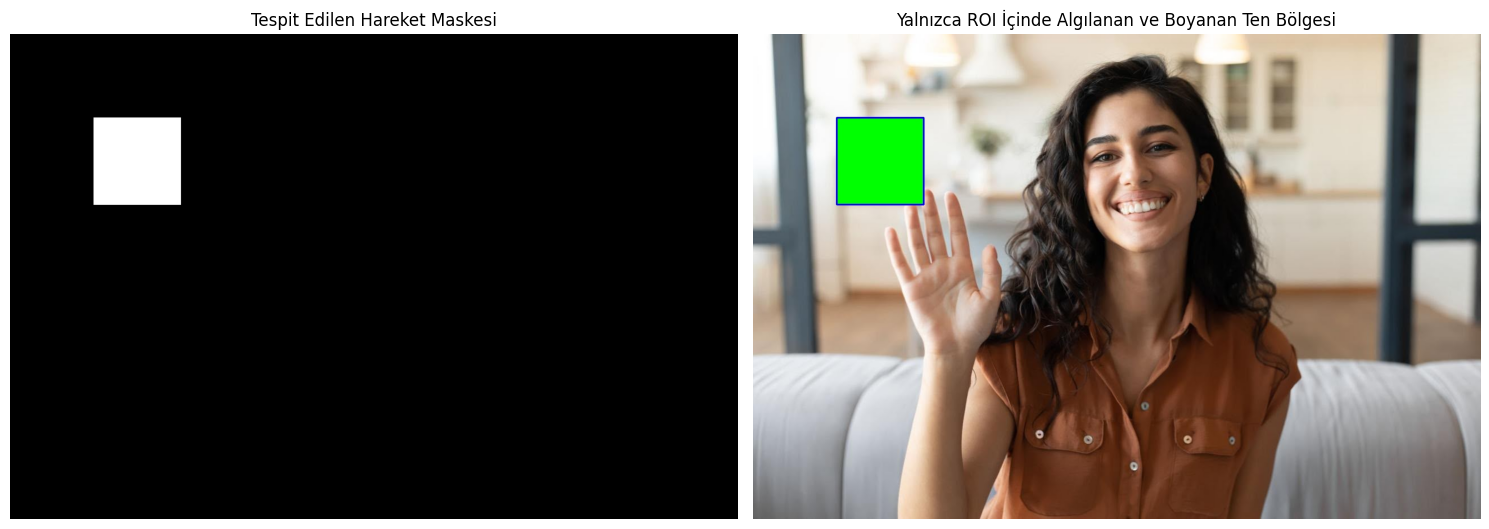

In [10]:
# Sonuçları görselleştirme
import matplotlib.pyplot as plt
import cv2

mask = cv2.imread('hareket_maskesi.jpg', cv2.IMREAD_GRAYSCALE)
result = cv2.imread('hareket_ve_ten_tespiti.jpg')

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
axes[0].imshow(mask, cmap='gray')
axes[0].set_title('Tespit Edilen Hareket Maskesi')
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
axes[1].set_title('Yalnızca ROI İçinde Algılanan ve Boyanan Ten Bölgesi')
axes[1].axis('off')

plt.tight_layout()
plt.show()